# ChurnGuard — Customer Churn Prediction & Retention Tool
**Week 2 · Machine Learning Internship · Due: 19 October 2026**

> This notebook is a **roadmap**. Every step is explained in words only. The code cells are empty on purpose — you write the code yourself.

## 0. The Big Picture

### What is the problem?
- A telecom company loses money when customers quietly leave. This is called **churn**.
- Finding a new customer costs much more than keeping an old one.
- The retention team cannot call everyone. They need to know **who** is likely to leave and **why**.

### What are we building?
- A model that gives each customer a **churn probability**.
- A **risk level** (Low / Medium / High) for each customer.
- The **top 3 reasons** why a customer is at risk (using SHAP).
- A **business decision**: which customers to target with an offer, and how much revenue this saves.
- A **Gradio app** (single customer + CSV upload), deployed on Hugging Face Spaces.

### The data
- Telco Customer Churn (IBM / Kaggle): 7043 customers, 21 columns.
- Target column: `Churn` (Yes / No). About **26.5%** of customers churn, so the data is **imbalanced**.
- There is no support-calls column. There is only `TechSupport` (Yes / No). We will mention this in the README limitations.

### What makes this project different from a normal classifier?
- **Accuracy is NOT our main metric.** A model that says "nobody churns" already gets about 73.5% accuracy and is useless.
- We care about **PR-AUC, recall and precision**.
- The decision threshold comes from **business cost**, not from the default 0.5.
- Every prediction must be **explainable**.

## 0.1 The Golden Rules (Read Before Writing Any Code)
These rules protect us from **data leakage**. Leakage means information from outside the training data sneaks into the model. It makes scores look great but the model fails in real life.

1. **Split first, then do everything else.** The test set is locked in a box until the very end.
2. **Every learned step lives inside a Pipeline.** Imputing, scaling, encoding and SMOTE are all learned only from the training part of each fold.
3. **SMOTE only inside the CV loop**, using the imbalanced-learn Pipeline. Never oversample before splitting.
4. **Choose the model, the tuning and the threshold using training data only** (cross-validation or out-of-fold predictions). Never use the test set for these choices.
5. **Touch the test set once**, at the very end, to report final honest numbers.
6. **Fix the random seed** everywhere so results can be repeated.
7. **Write every assumption down** (costs, offer success rate) so the README can be honest.

## 0.2 Tools and Concepts We Will Use

### Libraries
| Library | What we use it for |
|---|---|
| pandas, numpy | loading, cleaning and handling data |
| matplotlib, seaborn | EDA plots and result plots |
| scikit-learn | Pipeline, ColumnTransformer, imputers, scaler, one-hot encoder, models, CV, metrics, calibration |
| xgboost or lightgbm | the strong boosted-tree model (choose one) |
| imbalanced-learn | SMOTE and the imblearn Pipeline |
| shap | global and local explanations |
| gradio | the app (later, outside this notebook) |
| joblib | saving the final model |

### Concepts
- Classification, imbalanced data, class weights, SMOTE
- Stratified train/test split and Stratified K-Fold cross-validation
- Precision, recall, F1, ROC-AUC, **PR-AUC**, confusion matrix
- Hyperparameter tuning with cross-validation
- Probability calibration (sigmoid / isotonic, Brier score, calibration curve)
- Cost matrix and **cost-based threshold tuning**
- SHAP: global summary and local (per-customer) explanation
- Business impact: expected revenue saved

## 0.3 Pipeline Blueprint (What We Will Build)
The same idea is used for every model. Raw columns go in, probability comes out. Nothing is done outside the pipeline.

```
Pipeline
 |-- preprocessor (ColumnTransformer)
 |      |-- numeric columns      -> fill missing (blank TotalCharges = 0) -> scale (only for Logistic Regression)
 |      |-- binary column        -> pass through
 |      |-- categorical columns  -> fill missing -> one-hot encode
 |
 |-- (optional) SMOTE            -> only in the imblearn Pipeline, only on training folds
 |-- classifier                  -> Logistic Regression / Random Forest / XGBoost or LightGBM
```
- Because everything is inside one object, `cross_validate` re-learns every step for each fold. This is what stops leakage.
- The final pipeline can be saved as one file, so the app can take raw customer columns directly.

## 1. Setup and Imports
- We bring in all the libraries listed in section 0.2.
- We also define a small **config block** at the top: random seed, number of CV folds, and the business cost assumptions.
- Keeping all settings in one place makes it easy to move them to `src/config.py` later.

**Write in the cell below:** imports, the random seed, the CV fold count, and placeholders for the cost assumptions.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, cross_val_score, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, ConfusionMatrixDisplay, make_scorer)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from scipy.stats import randint, uniform
import shap, joblib

sns.set_theme(style="whitegrid")
for folder in ["models", "reports/figures", "data"]:
    os.makedirs(folder, exist_ok=True)

# ---- config ----
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"   # change this if your file is somewhere else
RANDOM_STATE = 42
N_FOLDS = 5
TARGET = "Churn"

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"reports/figures/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 2. Load the Data
- Load the Telco churn CSV file into a DataFrame.
- Look at the first few rows to feel the data.

**Write in the cell below:** read the CSV and show the first rows.

In [2]:
df = pd.read_csv(DATA_PATH)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. First Look at the Data
- Check the number of rows and columns (expect 7043 and 21).
- Check the data type of each column.
- Check missing values and duplicate rows.

**Things to notice:**
- `TotalCharges` is stored as text, not as a number. Find out why.
- `SeniorCitizen` is already 0/1 while the other yes/no columns are text.
- `customerID` is just an ID. It carries no real information.

In [3]:
print("Shape:", df.shape)
df.info()

Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Real NaN values:", df.isnull().sum().sum())
blank = df["TotalCharges"].astype(str).str.strip() == ""
print("Blank TotalCharges (hidden missing values):", blank.sum())
df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Duplicate rows: 0
Duplicate customer IDs: 0
Real NaN values: 0
Blank TotalCharges (hidden missing values): 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**What we found**
- 7043 rows and 21 columns, no duplicate rows and no duplicate customer IDs.
- `isnull()` shows zero missing values, but `TotalCharges` has **11 hidden blanks** (empty strings), which is why it is stored as text.
- All 11 of those customers have `tenure = 0`: they just joined and have not been billed yet.

## 4. Data Cleaning
- Convert `TotalCharges` to a number. About **11 rows** have a blank value.
- Look at those 11 rows. They all have `tenure = 0`, meaning brand new customers who have not been billed yet.
- Decide how to handle them (fill with 0 or drop). **Write your decision and reason in a markdown cell.**
- Drop `customerID`.
- Convert the target `Churn` from Yes/No to 1/0.
- The `TotalCharges` text-to-number conversion is a tiny, fixed rule (no learning), so it is safe to do here. The app will apply the same one-line conversion before predicting.

**Write in the cell below:** the cleaning steps, then check the shape again.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # blanks become NaN
df = df.drop(columns="customerID")
df[TARGET] = (df[TARGET] == "Yes").astype(int)

print("Shape after cleaning:", df.shape)
print("NaN left in TotalCharges:", df["TotalCharges"].isna().sum(), "(all have tenure = 0)")
print("Churn rate:", round(df[TARGET].mean(), 4))

Shape after cleaning: (7043, 20)
NaN left in TotalCharges: 11 (all have tenure = 0)
Churn rate: 0.2654


**Decisions**
- The 11 blank `TotalCharges` values become `NaN` and are filled with **0** inside the pipeline. This is a fixed rule (a brand-new customer has paid nothing), not something learned from the data, so it cannot leak.
- `customerID` is dropped because it is only an identifier.
- `Churn` is now 1 (left) / 0 (stayed).

## 5. Exploratory Data Analysis (EDA) — Churn Drivers
- The goal is to **explain why customers churn**, not just to draw many charts.
- For every chart, write one or two lines of insight in a markdown cell. These insights become the README story.

### 5.1 Target balance
- Count churned vs not churned customers and plot them.
- Calculate the churn rate (about 26.5%).
- Calculate the accuracy of a model that always says "No". This is our **dummy baseline**. It shows why accuracy is misleading.

Churn rate: 26.5%
Accuracy of a model that ALWAYS says 'No churn': 73.5%  <- the dummy baseline


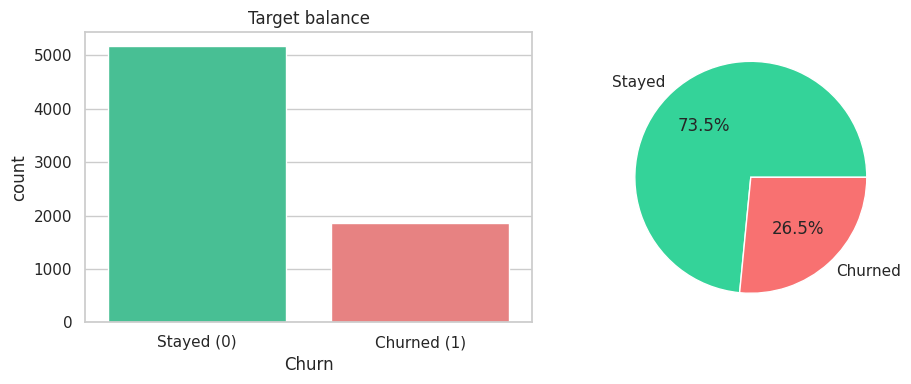

In [6]:
def churn_rate_bar(col, ax=None, order=None):
    """Churn rate (%) per category, with the number of customers on top of each bar."""
    ax = ax or plt.gca()
    g = df.groupby(col)[TARGET].agg(["mean", "count"]).mul([100, 1])
    if order is not None:
        g = g.loc[order]
    sns.barplot(x=g.index.astype(str), y=g["mean"], ax=ax, color="#7c5cff")
    for i, (rate, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(i, rate + 0.8, f"{rate:.1f}%\n(n={int(n)})", ha="center", fontsize=8)
    ax.axhline(df[TARGET].mean() * 100, color="red", ls="--", lw=1)
    ax.set_ylabel("Churn rate (%)"); ax.set_xlabel(col); ax.set_ylim(0, g["mean"].max() * 1.25)
    ax.tick_params(axis="x", rotation=15)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=TARGET, data=df, ax=ax[0], palette=["#34d399", "#f87171"])
ax[0].set_xticklabels(["Stayed (0)", "Churned (1)"]); ax[0].set_title("Target balance")
churn_rate = df[TARGET].mean()
print(f"Churn rate: {churn_rate:.1%}")
print(f"Accuracy of a model that ALWAYS says 'No churn': {1-churn_rate:.1%}  <- the dummy baseline")
df[TARGET].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[1], labels=["Stayed", "Churned"], colors=["#34d399", "#f87171"])
ax[1].set_ylabel("")
savefig("01_target_balance")

**Insight:** 26.5% of customers churn. A model that always answers "no churn" would be **73.5% accurate** and catch zero churners, so accuracy cannot be our main metric. The dummy PR-AUC baseline is the churn rate itself (about 0.265).

### 5.2 Contract type
- Plot churn rate for Month-to-month, One year and Two year contracts.
- Expected pattern: month-to-month customers churn far more than long-contract customers.

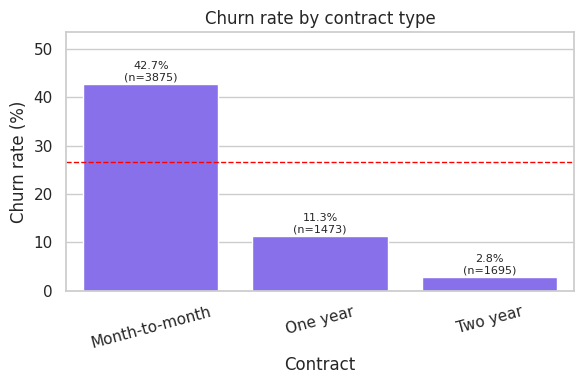

In [7]:
plt.figure(figsize=(6, 4))
churn_rate_bar("Contract", order=["Month-to-month", "One year", "Two year"])
plt.title("Churn rate by contract type")
savefig("02_contract")

**Insight:** contract type is the strongest single driver. Churn is **42.7%** for month-to-month, **11.3%** for one-year and only **2.8%** for two-year contracts. Month-to-month customers have no commitment, so they can leave at any time.

### 5.3 Tenure
- Compare the tenure of churned vs not churned customers.
- Group tenure into bins (for example 0–6, 7–12, 13–24, 25–48, 49–72 months) and plot churn rate per bin.
- Expected pattern: new customers are the most likely to leave.

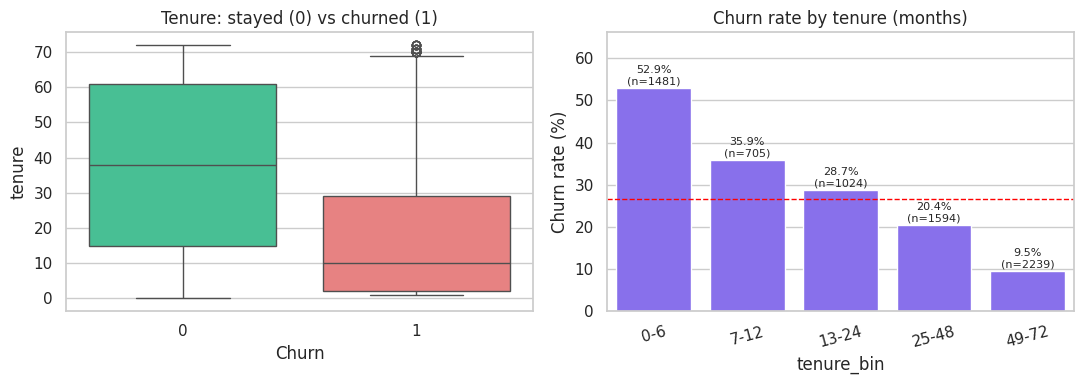

Churn
0    37.6
1    18.0
Name: tenure, dtype: float64


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=TARGET, y="tenure", data=df, ax=ax[0], palette=["#34d399", "#f87171"])
ax[0].set_title("Tenure: stayed (0) vs churned (1)")
df["tenure_bin"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
churn_rate_bar("tenure_bin", ax=ax[1])
ax[1].set_title("Churn rate by tenure (months)")
savefig("03_tenure")
print(df.groupby(TARGET)["tenure"].mean().round(1))
df = df.drop(columns="tenure_bin")   # helper column, not a model feature

**Insight:** churn falls steadily with tenure: **52.9%** for customers in their first 6 months, 35.9% (7-12), 28.7% (13-24), 20.4% (25-48) and only **9.5%** after 48 months. Churned customers stayed 18.0 months on average, loyal ones 37.6 months. The first months are the danger zone.

### 5.4 Charges
- Compare MonthlyCharges for churned vs not churned customers (boxplot or histogram).
- Look at TotalCharges too, and think about how it is related to tenure and MonthlyCharges.

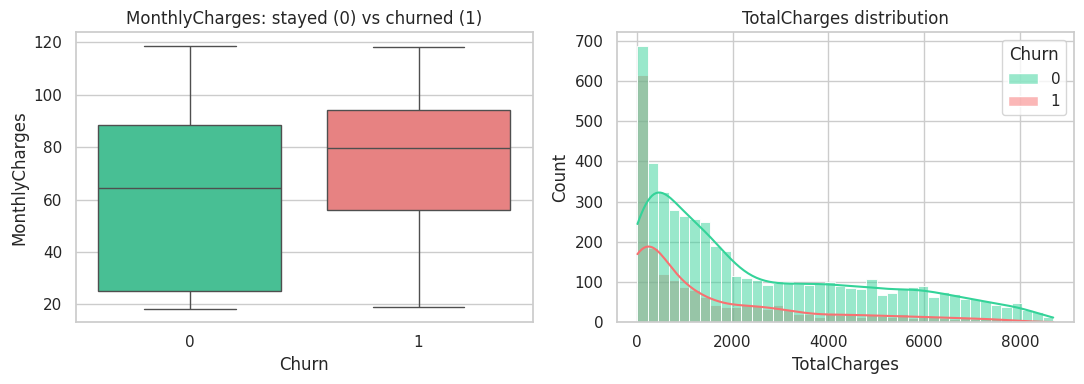

       MonthlyCharges  TotalCharges
Churn                              
0                61.3        2555.3
1                74.4        1531.8


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=TARGET, y="MonthlyCharges", data=df, ax=ax[0], palette=["#34d399", "#f87171"])
ax[0].set_title("MonthlyCharges: stayed (0) vs churned (1)")
sns.histplot(data=df, x="TotalCharges", hue=TARGET, bins=40, kde=True, ax=ax[1], palette=["#34d399", "#f87171"])
ax[1].set_title("TotalCharges distribution")
savefig("04_charges")
print(df.groupby(TARGET)[["MonthlyCharges", "TotalCharges"]].mean().round(1))

**Insight:** churners pay more per month (**74.4** on average vs 61.3 for customers who stay). Their `TotalCharges` is lower (1532 vs 2555), but that is mostly because they have a short tenure, not because they are cheaper customers.

### 5.5 Internet service, add-on services and payment method
- Plot churn rate by InternetService (DSL, Fiber optic, No).
- Plot churn rate by TechSupport and OnlineSecurity.
- Plot churn rate by PaymentMethod and PaperlessBilling.
- Look for groups with a clearly higher churn rate.

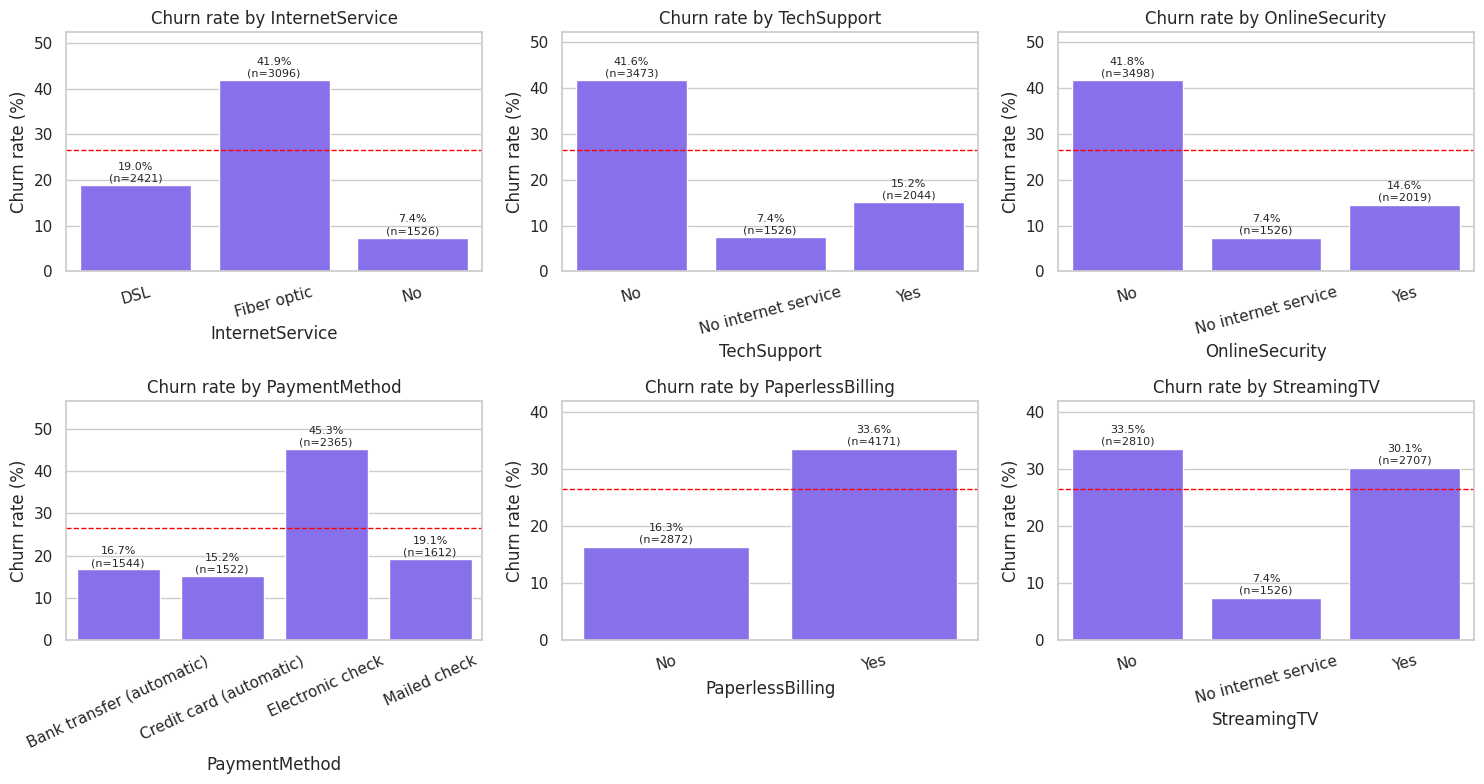

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["InternetService", "TechSupport", "OnlineSecurity", "PaymentMethod", "PaperlessBilling", "StreamingTV"]):
    churn_rate_bar(col, ax=ax)
    ax.set_title(f"Churn rate by {col}")
axes[1, 0].tick_params(axis="x", rotation=25)
savefig("05_services_payment")

**Insight**
- **Fiber optic** customers churn at 41.9%, DSL at 19.0% and customers without internet at 7.4%.
- Customers **without TechSupport** churn at 41.6% vs 15.2% with it. **Without OnlineSecurity**: 41.8% vs 14.6%.
- **Electronic check** users churn at 45.3%; automatic bank or card payment only 15-17%; mailed check 19.1%.
- Paperless billing: 33.6% vs 16.3% for paper billing.
- Streaming services (TV/movies) show only a small effect.

### 5.6 Customer profile
- Check churn by SeniorCitizen, Partner and Dependents.
- Check churn by gender. Gender should show almost no difference. Write this down as a **non-driver**.

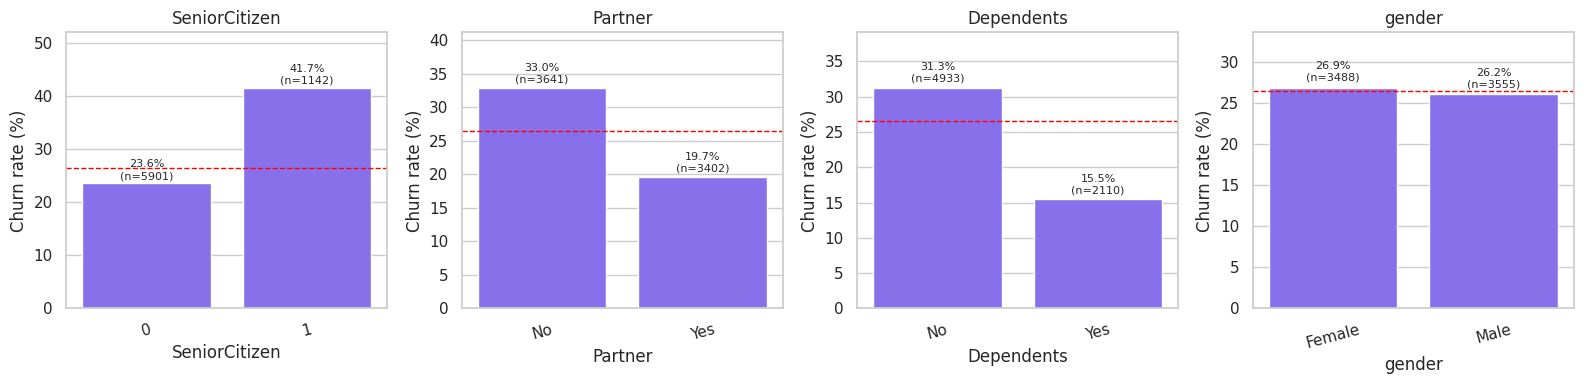

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["SeniorCitizen", "Partner", "Dependents", "gender"]):
    churn_rate_bar(col, ax=ax)
    ax.set_title(col)
savefig("06_profile")

**Insight**
- Senior citizens churn at 41.7% vs 23.6% for the rest.
- Customers without a partner churn at 33.0% (vs 19.7%) and without dependents at 31.3% (vs 15.5%).
- **Gender is a non-driver**: 26.9% for females vs 26.2% for males. This is a nice sanity check: a fair model should not rely on it.

### 5.7 Correlation and redundancy
- Check correlation between the numeric columns.
- `TotalCharges` is close to `tenure x MonthlyCharges`. Think about what this means for Logistic Regression and for SHAP.
- Write down any idea you want to test later (for example: with and without TotalCharges).

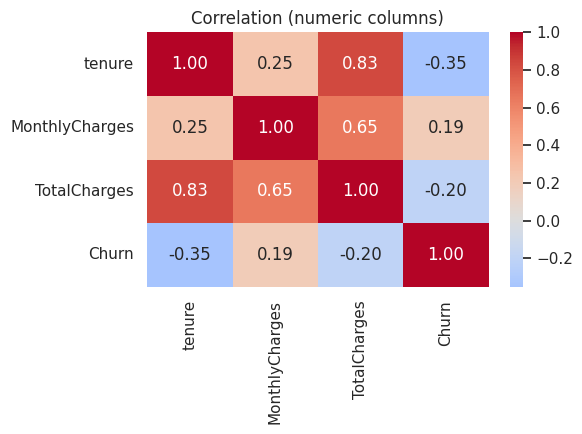

Correlation of TotalCharges with tenure x MonthlyCharges: 1.0


In [12]:
num_check = df[["tenure", "MonthlyCharges", "TotalCharges", TARGET]]
plt.figure(figsize=(6, 4.5))
sns.heatmap(num_check.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (numeric columns)")
savefig("07_correlation")
approx = df["tenure"] * df["MonthlyCharges"]
print("Correlation of TotalCharges with tenure x MonthlyCharges:",
      round(np.corrcoef(approx[df["TotalCharges"].notna()], df["TotalCharges"].dropna())[0, 1], 3))

**Insight**
- `TotalCharges` is almost exactly `tenure x MonthlyCharges` (correlation about 1.0 with that product), and it is also correlated with tenure (0.83) and MonthlyCharges (0.65). It carries little new information, which is something to remember for Logistic Regression coefficients and for SHAP (credit can be split between these features).
- `tenure` has the strongest negative correlation with churn (-0.35).

### 5.8 EDA summary
**Write in a markdown cell below:** the top 5 churn drivers you found, in your own words, with numbers.

**EDA summary: the top churn drivers**
1. **Month-to-month contract**: 42.7% churn vs 2.8% for two-year contracts.
2. **Short tenure**: 52.9% churn in the first 6 months, 9.5% after 48 months.
3. **Fiber optic internet**: 41.9% churn, and customers without TechSupport or OnlineSecurity churn about 42%.
4. **Electronic check payment**: 45.3% churn vs about 15-17% for automatic payments.
5. **Higher monthly charges, senior citizens and customers without partner or dependents** churn more. Gender does not matter.

The typical high-risk customer is a **new, month-to-month, fiber-optic customer paying by electronic check without add-on services**.

## 6. Business Costs and Assumptions
- A churn model is only useful if it leads to a good decision. Decisions cost money.
- Define the cost of each outcome:

| Outcome | Meaning | Cost / benefit idea |
|---|---|---|
| False Negative | customer was going to leave, we did nothing | we lose the customer's revenue (big loss) |
| False Positive | customer was staying, we gave an offer anyway | we waste the offer cost (small loss) |
| True Positive | we targeted a real churner | we pay the offer cost, and save the customer only if the offer works |
| True Negative | no action, customer stays | no cost |

- This dataset has no cost columns, so we must **make assumptions**:
  - Customer value (for example MonthlyCharges x a number of months)
  - Offer cost (for example a discount or a fixed amount)
  - Offer success rate (not every offer works)
- **Write all assumptions clearly.** In the README they are labeled as assumptions, and we will test a few different values later.

**Write in the cell below:** store the assumptions as named variables.

In [13]:
# ---- BUSINESS ASSUMPTIONS (these are assumptions, not facts from the data) ----
VALUE_MONTHS = 12      # value of a customer = MonthlyCharges x 12 months of revenue
OFFER_COST = 100       # cost of one retention offer (for example a bill credit or discount)
OFFER_SUCCESS = 0.30   # share of real churners who stay when they get an offer

def customer_value(monthly_charges):
    return np.asarray(monthly_charges) * VALUE_MONTHS

def total_cost(y_true, proba, threshold, value, offer_cost=None, success=None):
    """Total business cost if we send an offer to everyone with proba >= threshold.
    - not flagged + churned          -> we lose the full customer value (False Negative)
    - flagged                        -> we pay the offer cost (True and False Positives)
    - flagged + churned + offer fails -> we still lose the customer value
    """
    offer_cost = OFFER_COST if offer_cost is None else offer_cost
    success = OFFER_SUCCESS if success is None else success
    y = np.asarray(y_true); v = np.asarray(value); flag = np.asarray(proba) >= threshold
    missed = (v * y)[~flag].sum()
    offers = offer_cost * flag.sum()
    failed = ((1 - success) * v * y)[flag].sum()
    return missed + offers + failed

avg_value = customer_value(df["MonthlyCharges"]).mean()
print(f"Average customer value: {avg_value:,.0f}")
print(f"Break-even churn probability for an average customer: {OFFER_COST / (OFFER_SUCCESS * avg_value):.2f}")

Average customer value: 777
Break-even churn probability for an average customer: 0.43


**Reading the numbers:** with these assumptions the average customer is worth about 780 and an offer costs 100, so it pays to send an offer when the churn probability is above roughly 0.43 (for an average customer). This is only the starting intuition. Section 18 finds the best threshold from real data. Remember, all three numbers are **assumptions** and are shown again in the README.

## 7. Features, Target and Train-Test Split
- Separate the input features from the target.
- Do a **stratified** split (for example 80% train / 20% test) so both parts keep the same churn rate.
- Check the churn rate in both parts to confirm.
- **From now on, the test set is locked.** We do not plot it, tune on it or peek at it.

**Write in the cell below:** the features/target separation, the stratified split, and the churn-rate check.

In [14]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_tr.shape, "| churn rate:", round(y_tr.mean(), 4))
print("Test :", X_te.shape, "| churn rate:", round(y_te.mean(), 4))

neg, pos = np.bincount(y_tr)
SPW = neg / pos            # scale_pos_weight for XGBoost
print("scale_pos_weight (neg/pos):", round(SPW, 2))
value_tr = customer_value(X_tr["MonthlyCharges"])
value_te = customer_value(X_te["MonthlyCharges"])
# From here on the test set (X_te, y_te) stays locked until section 19.

Train: (5634, 19) | churn rate: 0.2654
Test : (1409, 19) | churn rate: 0.2654
scale_pos_weight (neg/pos): 2.77


## 8. Column Groups
- Make three lists of column names:
  - **Numeric:** tenure, MonthlyCharges, TotalCharges
  - **Binary (already 0/1):** SeniorCitizen
  - **Categorical:** the remaining 15 text columns
- Double check that every feature belongs to exactly one list (19 features in total).

**Write in the cell below:** the three lists and a quick count check.

In [15]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
bin_cols = ["SeniorCitizen"]
cat_cols = [c for c in X.columns if c not in num_cols + bin_cols]

print("Numeric    :", num_cols)
print("Binary     :", bin_cols)
print("Categorical:", len(cat_cols), cat_cols)
assert len(num_cols + bin_cols + cat_cols) == X.shape[1] == 19
assert set(num_cols + bin_cols + cat_cols) == set(X.columns)

Numeric    : ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary     : ['SeniorCitizen']
Categorical: 15 ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 9. Preprocessing with ColumnTransformer and Pipelines
- Different column types need different treatment, so we use a ColumnTransformer.
- We build **two versions** of the preprocessor:

### 9.1 For Logistic Regression
- Numeric: convert to number, fill missing values, **scale**.
- Binary: pass through.
- Categorical: fill missing values, one-hot encode (ignore unseen categories, return a dense array).

### 9.2 For tree models (Random Forest, XGBoost / LightGBM)
- Same as above but **no scaling**, because trees do not need it.

**Things to think about:**
- Why do we fill missing numeric values with a fixed value or the training median, and not the median of the full data?
- Why should the one-hot encoder ignore unseen categories? (Think about the app.)
- Why do we want clean feature names after encoding? (Think about SHAP.)

**Write in the cell below:** both preprocessors. Fit nothing yet.

In [16]:
def make_preprocessor(scale):
    """ColumnTransformer. scale=True for Logistic Regression, scale=False for tree models."""
    num_steps = [("imputer", SimpleImputer(strategy="constant", fill_value=0))]   # blank TotalCharges = new customer = 0
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(num_steps), num_cols),
            ("bin", "passthrough", bin_cols),
            ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,     # clean names for SHAP, e.g. Contract_Two year
    )

preprocessor_lr = make_preprocessor(scale=True)     # Logistic Regression
preprocessor_tree = make_preprocessor(scale=False)  # Random Forest, XGBoost
preprocessor_lr

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant')),
                                                 ('scaler', StandardScaler())]),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                ('bin', 'passthrough', ['SeniorCitizen']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])],
                  verbose_feature_names_out=False)

## 10. Evaluation Metrics and a Helper Function
### Metrics in plain words
- **Precision:** of the customers we flagged as churners, how many really churned?
- **Recall:** of all real churners, how many did we catch?
- **F1:** a balance between precision and recall.
- **ROC-AUC:** how well the model ranks churners above non-churners, but it can look too optimistic on imbalanced data.
- **PR-AUC (average precision):** the most honest summary for imbalanced data. **This is our main metric.**
- **Confusion matrix:** the four counts (TN, FP, FN, TP) that connect the model to business cost.

### Helper function plan
**Write one reusable function** that takes a model, data and a threshold and shows: precision, recall, F1, ROC-AUC, PR-AUC, the confusion matrix and the PR curve. Keep accuracy only as a side note.

In [17]:
def evaluate_model(name, model, X, y, threshold=0.5, plot=True):
    """Metrics + confusion matrix + PR curve for any fitted model that has predict_proba."""
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    res = {
        "model": name, "threshold": round(threshold, 3),
        "pr_auc": average_precision_score(y, proba), "roc_auc": roc_auc_score(y, proba),
        "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
        "f1": f1_score(y, pred), "brier": brier_score_loss(y, proba),
    }
    print(f"{name} @ threshold {threshold:.2f}")
    print("  " + " | ".join(f"{k}: {v:.3f}" for k, v in res.items() if k not in ("model", "threshold")))
    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ConfusionMatrixDisplay.from_predictions(y, pred, ax=ax[0], colorbar=False, cmap="Blues")
        ax[0].set_title("Confusion matrix")
        p, r, _ = precision_recall_curve(y, proba)
        ax[1].plot(r, p, color="#7c5cff", label=f"PR-AUC = {res['pr_auc']:.3f}")
        ax[1].axhline(np.mean(y), color="gray", ls="--", label="No-skill (churn rate)")
        ax[1].scatter([res["recall"]], [res["precision"]], color="red", zorder=5, label="chosen threshold")
        ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend(); ax[1].set_title("Precision-Recall curve")
        plt.tight_layout(); plt.show()
    return res

## 11. Stratified Cross-Validation Setup
- One train/validation split can be lucky or unlucky. Cross-validation is more reliable.
- Use **Stratified K-Fold** (5 folds, shuffled, fixed seed) so each fold keeps the churn ratio.
- Define the list of scores to collect: PR-AUC (main), ROC-AUC, recall, precision and F1.
- Report **mean and standard deviation** for each score. With 7k rows, the standard deviation matters.

In [18]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "pr_auc": "average_precision",          # MAIN metric
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": "f1",
}
results = []     # every experiment is stored here

def run_cv(model_name, strategy, pipe):
    """Stratified CV on the TRAINING set only. Stores mean and std of every metric."""
    out = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": model_name, "strategy": strategy}
    for k in scoring:
        row[k + "_mean"] = out["test_" + k].mean()
        row[k + "_std"] = out["test_" + k].std()
    results.append(row)
    return row

def results_table():
    r = pd.DataFrame(results)
    t = r[["model", "strategy"]].copy()
    for k in scoring:
        t[k] = r[k + "_mean"].round(3).astype(str) + " ± " + r[k + "_std"].round(3).astype(str)
    return t.iloc[np.argsort(-r["pr_auc_mean"].values)].reset_index(drop=True)

# quick look at the folds: churn rate must be almost the same in every fold
for i, (a, b) in enumerate(cv.split(X_tr, y_tr), 1):
    print(f"Fold {i}: validation size {len(b)}, churn rate {y_tr.iloc[b].mean():.3f}")

Fold 1: validation size 1127, churn rate 0.265
Fold 2: validation size 1127, churn rate 0.265
Fold 3: validation size 1127, churn rate 0.265
Fold 4: validation size 1127, churn rate 0.265
Fold 5: validation size 1126, churn rate 0.266


## 12. Baseline Model
- Build a **Dummy classifier** inside a pipeline.
- Get its cross-validated PR-AUC. It will be close to the churn rate (about 0.27). This is the **floor**. Any real model must beat it.
- Write one line about why its accuracy looks good but means nothing.

In [19]:
baseline_pipe = Pipeline([("prep", make_preprocessor(scale=False)),
                          ("clf", DummyClassifier(strategy="prior"))])
run_cv("Dummy", "baseline", baseline_pipe)
results_table()

,model,strategy,pr_auc,roc_auc,recall,precision,f1
0,Dummy,baseline,0.265 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0


In [20]:
# why accuracy is misleading: the dummy model "predicts nobody churns"
baseline_pipe.fit(X_tr, y_tr)
dummy_pred = baseline_pipe.predict(X_tr)
print("Dummy accuracy on train:", round((dummy_pred == y_tr).mean(), 3), "<- looks good but catches 0 churners")
print("Dummy recall:", recall_score(y_tr, dummy_pred))

Dummy accuracy on train: 0.735 <- looks good but catches 0 churners
Dummy recall: 0.0


## 13. Compare at Least 3 Models
Build one pipeline for each model and run the same cross-validation for all of them.

1. **Logistic Regression** (with the scaled preprocessor): simple and easy to explain.
2. **Random Forest:** a strong non-linear model.
3. **XGBoost or LightGBM:** the usual winner on tabular data and works nicely with SHAP.

- Put all results in **one table** (model vs scores, mean ± std).
- If two models are within one standard deviation of each other, say honestly that there is **no clear winner**.

In [21]:
def build_pipe(model_name, strategy="none"):
    """strategy: none | weights | smote.  SMOTE (imblearn Pipeline) runs only on training folds."""
    if model_name == "LogReg":
        prep = make_preprocessor(scale=True)
        clf = LogisticRegression(max_iter=2000, class_weight="balanced" if strategy == "weights" else None,
                                 random_state=RANDOM_STATE)
    elif model_name == "RandomForest":
        prep = make_preprocessor(scale=False)
        clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE,
                                     class_weight="balanced_subsample" if strategy == "weights" else None)
    elif model_name == "XGBoost":
        prep = make_preprocessor(scale=False)
        clf = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                            eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,
                            scale_pos_weight=SPW if strategy == "weights" else 1)
    else:
        raise ValueError(model_name)
    if strategy == "smote":
        return ImbPipeline([("prep", prep), ("smote", SMOTE(random_state=RANDOM_STATE)), ("clf", clf)])
    return Pipeline([("prep", prep), ("clf", clf)])

for m in ["LogReg", "RandomForest", "XGBoost"]:
    run_cv(m, "none", build_pipe(m, "none"))
results_table()

,model,strategy,pr_auc,roc_auc,recall,precision,f1
0,XGBoost,none,0.664 ± 0.018,0.844 ± 0.01,0.522 ± 0.027,0.66 ± 0.029,0.582 ± 0.023
1,LogReg,none,0.662 ± 0.019,0.846 ± 0.013,0.544 ± 0.041,0.654 ± 0.027,0.593 ± 0.03
2,RandomForest,none,0.655 ± 0.021,0.845 ± 0.009,0.496 ± 0.021,0.673 ± 0.028,0.571 ± 0.021
3,Dummy,baseline,0.265 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0


**Reading the table:** the three models are very close (PR-AUC about 0.655-0.664, standard deviation about 0.02). The differences are **within the noise**, so no model is a clear winner. Logistic Regression is as good as XGBoost here, which tells us the signal in this dataset is mostly simple and fairly linear.

## 14. Handling Class Imbalance
### 14.1 Class weights
- Tell the model that mistakes on churners cost more (`class_weight` for sklearn models, `scale_pos_weight` for XGBoost).
- The weight for XGBoost can be calculated from the training class counts.
- Cross-validate each model again with class weights.

### 14.2 SMOTE (inside the CV loop only)
- SMOTE creates synthetic churner rows to balance the data.
- **It must run only on the training folds.** Use the imbalanced-learn Pipeline so that SMOTE is applied after preprocessing and only while fitting.
- Never apply SMOTE to the full data before splitting. This is the most common leakage mistake.

### 14.3 Compare
- Make a table: no imbalance handling vs class weights vs SMOTE, for the same model(s).
- Compare PR-AUC, recall and precision.
- **Write your conclusion honestly**, even if SMOTE does not help.

#### 14.1 Class weights

In [22]:
for m in ["LogReg", "RandomForest", "XGBoost"]:
    run_cv(m, "weights", build_pipe(m, "weights"))
results_table()

,model,strategy,pr_auc,roc_auc,recall,precision,f1
0,XGBoost,none,0.664 ± 0.018,0.844 ± 0.01,0.522 ± 0.027,0.66 ± 0.029,0.582 ± 0.023
1,XGBoost,weights,0.663 ± 0.02,0.844 ± 0.01,0.777 ± 0.026,0.532 ± 0.014,0.631 ± 0.017
2,LogReg,none,0.662 ± 0.019,0.846 ± 0.013,0.544 ± 0.041,0.654 ± 0.027,0.593 ± 0.03
3,LogReg,weights,0.66 ± 0.02,0.846 ± 0.012,0.801 ± 0.038,0.517 ± 0.019,0.628 ± 0.023
4,RandomForest,none,0.655 ± 0.021,0.845 ± 0.009,0.496 ± 0.021,0.673 ± 0.028,0.571 ± 0.021
5,RandomForest,weights,0.654 ± 0.02,0.845 ± 0.008,0.731 ± 0.029,0.561 ± 0.01,0.634 ± 0.013
6,Dummy,baseline,0.265 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0


#### 14.2 SMOTE inside the CV loop (imblearn Pipeline, training folds only)

In [23]:
for m in ["LogReg", "RandomForest", "XGBoost"]:
    run_cv(m, "smote", build_pipe(m, "smote"))
results_table()

,model,strategy,pr_auc,roc_auc,recall,precision,f1
0,XGBoost,none,0.664 ± 0.018,0.844 ± 0.01,0.522 ± 0.027,0.66 ± 0.029,0.582 ± 0.023
1,XGBoost,weights,0.663 ± 0.02,0.844 ± 0.01,0.777 ± 0.026,0.532 ± 0.014,0.631 ± 0.017
2,LogReg,none,0.662 ± 0.019,0.846 ± 0.013,0.544 ± 0.041,0.654 ± 0.027,0.593 ± 0.03
3,LogReg,weights,0.66 ± 0.02,0.846 ± 0.012,0.801 ± 0.038,0.517 ± 0.019,0.628 ± 0.023
4,LogReg,smote,0.658 ± 0.023,0.845 ± 0.013,0.789 ± 0.04,0.526 ± 0.018,0.631 ± 0.023
5,XGBoost,smote,0.657 ± 0.024,0.844 ± 0.01,0.561 ± 0.021,0.637 ± 0.019,0.596 ± 0.014
6,RandomForest,none,0.655 ± 0.021,0.845 ± 0.009,0.496 ± 0.021,0.673 ± 0.028,0.571 ± 0.021
7,RandomForest,weights,0.654 ± 0.02,0.845 ± 0.008,0.731 ± 0.029,0.561 ± 0.01,0.634 ± 0.013
8,RandomForest,smote,0.634 ± 0.027,0.84 ± 0.009,0.572 ± 0.021,0.621 ± 0.024,0.595 ± 0.015
9,Dummy,baseline,0.265 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0


#### 14.3 Side-by-side comparison

PR-AUC (mean):


strategy,none,weights,smote
model,,,
LogReg,0.662,0.660,0.658
RandomForest,0.655,0.654,0.634
XGBoost,0.664,0.663,0.657


Recall at threshold 0.5 (mean):


strategy,none,weights,smote
model,,,
LogReg,0.544,0.801,0.789
RandomForest,0.496,0.731,0.572
XGBoost,0.522,0.777,0.561


Precision at threshold 0.5 (mean):


strategy,none,weights,smote
model,,,
LogReg,0.654,0.517,0.526
RandomForest,0.673,0.561,0.621
XGBoost,0.660,0.532,0.637


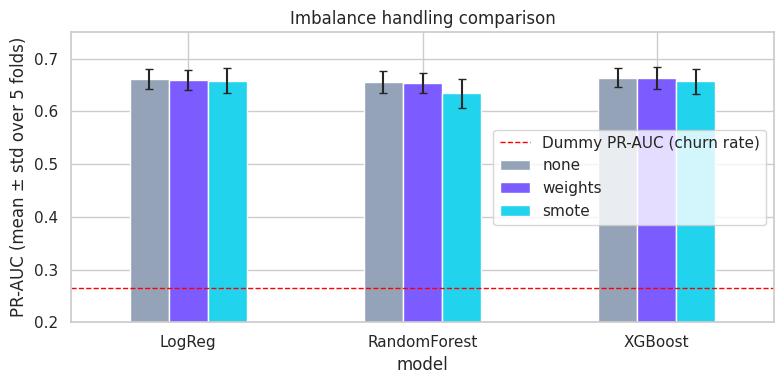

In [24]:
res = pd.DataFrame(results)
res_main = res[res.model != "Dummy"]
mean_tab = res_main.pivot(index="model", columns="strategy", values="pr_auc_mean")[["none", "weights", "smote"]]
std_tab = res_main.pivot(index="model", columns="strategy", values="pr_auc_std")[["none", "weights", "smote"]]
print("PR-AUC (mean):"); display(mean_tab.round(3))
print("Recall at threshold 0.5 (mean):")
display(res_main.pivot(index="model", columns="strategy", values="recall_mean")[["none", "weights", "smote"]].round(3))
print("Precision at threshold 0.5 (mean):")
display(res_main.pivot(index="model", columns="strategy", values="precision_mean")[["none", "weights", "smote"]].round(3))

ax = mean_tab.plot(kind="bar", yerr=std_tab, capsize=3, figsize=(8, 4), rot=0, color=["#94a3b8", "#7c5cff", "#22d3ee"])
ax.axhline(y_tr.mean(), color="red", ls="--", lw=1, label="Dummy PR-AUC (churn rate)")
ax.set_ylim(0.2, 0.75); ax.set_ylabel("PR-AUC (mean ± std over 5 folds)"); ax.legend()
ax.set_title("Imbalance handling comparison")
savefig("08_imbalance_comparison")

**Conclusion (honest version)**
- **Class weights** do not improve PR-AUC (0.663 vs 0.664 for XGBoost). They only move the operating point: recall at threshold 0.5 jumps from 0.52 to 0.78 and precision drops from 0.66 to 0.53. Threshold tuning (section 18) does the same job in a more controlled way.
- **SMOTE** did not help either: PR-AUC is equal or slightly lower, and it was clearly worst for Random Forest (0.634). XGBoost with SMOTE gets recall of only 0.56.
- Because SMOTE ran inside the CV loop, these numbers are honest. Doing SMOTE before splitting would have given inflated scores.

## 15. Choose the Best Model
- Pick the final model and imbalance method using the cross-validation table only.
- Write the reason in 2–3 lines (metric values, stability, how easy it is to explain, speed).
- Do **not** look at the test set to decide.

In [25]:
res = pd.DataFrame(results)
main = res[res.model != "Dummy"].sort_values("pr_auc_mean", ascending=False)
top = main.iloc[0]
close = main[main.pr_auc_mean >= top.pr_auc_mean - top.pr_auc_std]      # within one std of the best = statistically tied
print(f"Best PR-AUC: {top.model} + {top.strategy} = {top.pr_auc_mean:.3f} (std {top.pr_auc_std:.3f})")
print("Experiments within one std of the best (practically tied):")
display(close[["model", "strategy", "pr_auc_mean", "pr_auc_std", "recall_mean", "precision_mean"]].round(3))

# Tie-break rule: among tied experiments prefer XGBoost (works with SHAP TreeExplainer and matches the project brief)
xgb_close = close[close.model == "XGBoost"]
chosen = xgb_close.iloc[0] if len(xgb_close) else top
BEST_MODEL, BEST_STRATEGY = chosen.model, chosen.strategy
print(f"\nCHOSEN -> {BEST_MODEL} with strategy '{BEST_STRATEGY}'")

Best PR-AUC: XGBoost + none = 0.664 (std 0.018)
Experiments within one std of the best (practically tied):


,model,strategy,pr_auc_mean,pr_auc_std,recall_mean,precision_mean
3,XGBoost,none,0.664,0.018,0.522,0.660
6,XGBoost,weights,0.663,0.020,0.777,0.532
1,LogReg,none,0.662,0.019,0.544,0.654
4,LogReg,weights,0.660,0.020,0.801,0.517
7,LogReg,smote,0.658,0.023,0.789,0.526
9,XGBoost,smote,0.657,0.024,0.561,0.637
2,RandomForest,none,0.655,0.021,0.496,0.673
5,RandomForest,weights,0.654,0.020,0.731,0.561



CHOSEN -> XGBoost with strategy 'none'


**Decision:** the best mean PR-AUC is XGBoost without any imbalance handling (0.664), but eight experiments are within one standard deviation of it, so they are statistically tied. The tie-break rule (written before the run) prefers **XGBoost**, because it works with the SHAP tree explainer and matches the project brief. We stay with XGBoost and no class weights or SMOTE, and handle the imbalance with the cost-based threshold instead.

## 16. Hyperparameter Tuning (Optional but Recommended)
- Use a randomized search with cross-validation on the **training set**.
- Use **PR-AUC (average precision)** as the scoring metric.
- Keep the search small and reasonable. The goal is a slightly better model, not a long run.
- Compare the tuned score with the untuned score. If the gain is within the noise, say so.

In [26]:
base_pipe = build_pipe(BEST_MODEL, BEST_STRATEGY)
FINAL_PIPE = base_pipe          # default, may be replaced below

if BEST_MODEL == "XGBoost":
    param_dist = {
        "clf__n_estimators": randint(150, 600),
        "clf__max_depth": randint(2, 7),
        "clf__learning_rate": uniform(0.01, 0.19),
        "clf__subsample": uniform(0.6, 0.4),
        "clf__colsample_bytree": uniform(0.5, 0.5),
        "clf__min_child_weight": randint(1, 10),
        "clf__reg_lambda": uniform(0.5, 5),
    }
    search = RandomizedSearchCV(base_pipe, param_dist, n_iter=20, scoring="average_precision",
                                cv=cv, n_jobs=-1, random_state=RANDOM_STATE, refit=False)
    search.fit(X_tr, y_tr)
    print("Best CV PR-AUC inside the search:", round(search.best_score_, 4))
    print("Best params:", {k.replace("clf__", ""): (round(float(v), 3) if isinstance(v, (float, np.floating)) else int(v))
                           for k, v in search.best_params_.items()})
    tuned_pipe = clone(base_pipe).set_params(**search.best_params_)

    # The best score inside a search is optimistic. Compare tuned vs untuned again on NEW folds.
    cv_new = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=7)
    base_new = cross_val_score(base_pipe, X_tr, y_tr, cv=cv_new, scoring="average_precision", n_jobs=-1)
    tuned_new = cross_val_score(tuned_pipe, X_tr, y_tr, cv=cv_new, scoring="average_precision", n_jobs=-1)
    print(f"Fresh folds -> untuned: {base_new.mean():.4f} ± {base_new.std():.4f} | tuned: {tuned_new.mean():.4f} ± {tuned_new.std():.4f}")
    if tuned_new.mean() > base_new.mean():
        FINAL_PIPE = tuned_pipe
        print("-> keeping the TUNED pipeline")
    else:
        print("-> tuning did not help on fresh folds, keeping the UNTUNED pipeline")
else:
    print("Tuning code is written for XGBoost; keeping the pipeline as it is.")

Best CV PR-AUC inside the search: 0.6712
Best params: {'colsample_bytree': 0.736, 'learning_rate': 0.033, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 154, 'reg_lambda': 3.306, 'subsample': 0.908}
Fresh folds -> untuned: 0.6603 ± 0.0272 | tuned: 0.6681 ± 0.0260
-> keeping the TUNED pipeline


**Reading the result:** on fresh folds the tuned model scores 0.668 vs 0.660 untuned, but the standard deviation is about 0.027. The gain is **small and within the noise**. We keep the tuned pipeline by the rule above, but the README should not claim a real improvement.

## 17. Probability Calibration
- A model that says 0.30 should be right about 30% of the time. Many models do not do this.
- Our cost calculation depends on the probabilities, so they must be trustworthy.

**Steps**
- Get **out-of-fold** probabilities from the training data (predictions made on data the model did not train on).
- Plot a calibration curve and calculate the Brier score.
- Wrap the best pipeline with a calibrator (sigmoid and isotonic) and compare the Brier score before vs after.
- Use a clear rule: calibrate only if it really improves the Brier score. If the raw model is already calibrated, say so and keep it.

In [27]:
# Out-of-fold (OOF) probabilities: every training row is predicted by a model that did NOT see it
oof_raw = cross_val_predict(clone(FINAL_PIPE), X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
oof_cal = {}
for method in ["sigmoid", "isotonic"]:
    cal = CalibratedClassifierCV(clone(FINAL_PIPE), method=method, cv=5)
    oof_cal[method] = cross_val_predict(cal, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

brier = pd.Series({
    "uncalibrated": brier_score_loss(y_tr, oof_raw),
    "sigmoid": brier_score_loss(y_tr, oof_cal["sigmoid"]),
    "isotonic": brier_score_loss(y_tr, oof_cal["isotonic"]),
})
print("Brier score (lower is better):"); print(brier.round(4))
print("Mean predicted probability:", {k: round(float(v.mean()), 3) for k, v in
      {"uncalibrated": oof_raw, "sigmoid": oof_cal["sigmoid"], "isotonic": oof_cal["isotonic"]}.items()},
      "| real churn rate:", round(y_tr.mean(), 3))

Brier score (lower is better):
uncalibrated    0.1334
sigmoid         0.1346
isotonic        0.1333
dtype: float64
Mean predicted probability: {'uncalibrated': 0.265, 'sigmoid': 0.265, 'isotonic': 0.265} | real churn rate: 0.265


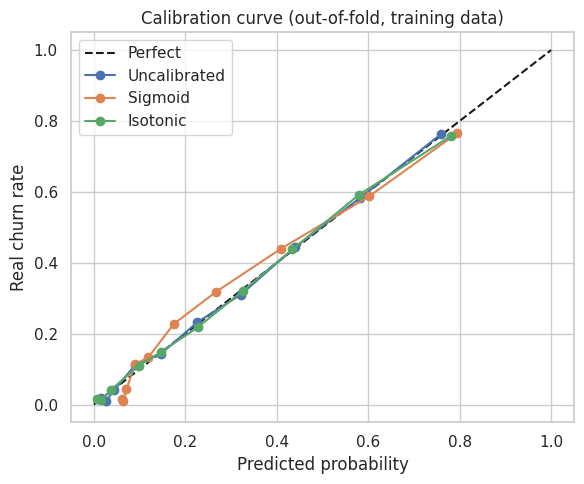

In [28]:
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
for label, p in [("Uncalibrated", oof_raw), ("Sigmoid", oof_cal["sigmoid"]), ("Isotonic", oof_cal["isotonic"])]:
    frac_pos, mean_pred = calibration_curve(y_tr, p, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_pos, "o-", label=label)
plt.xlabel("Predicted probability"); plt.ylabel("Real churn rate"); plt.legend(); plt.title("Calibration curve (out-of-fold, training data)")
savefig("09_calibration")

In [29]:
# Decision rules (written BEFORE looking at the final answer):
# 1) prefer the smooth sigmoid; use isotonic only if it is clearly better (isotonic gives step-shaped probabilities, many exact 0.00 / 1.00)
# 2) calibrate at all only if it improves the Brier score by more than 0.002 compared with the raw model
candidate = "sigmoid" if brier["sigmoid"] - 0.005 <= brier["isotonic"] else "isotonic"
USE_CALIBRATION = brier[candidate] < brier["uncalibrated"] - 0.002
CAL_METHOD = candidate if USE_CALIBRATION else "none"
OOF_PROBA = oof_cal[candidate] if USE_CALIBRATION else oof_raw
print("Best calibration candidate:", candidate, "| Brier:", round(brier[candidate], 4), "vs raw:", round(brier["uncalibrated"], 4))
print("Use calibration?", USE_CALIBRATION, "->", "calibrated with " + CAL_METHOD if USE_CALIBRATION else "keep the raw probabilities (already well calibrated)")

Best calibration candidate: sigmoid | Brier: 0.1346 vs raw: 0.1334
Use calibration? False -> keep the raw probabilities (already well calibrated)


**Decision: no calibration needed.**
- The raw XGBoost probabilities are already well calibrated: Brier score 0.1334 (raw) vs 0.1346 (sigmoid) vs 0.1333 (isotonic), and the average predicted probability equals the real churn rate (0.265).
- Isotonic is not better in any meaningful way and gives step-shaped probabilities (many exact 0.00 and 1.00), which look strange for a single customer. Sigmoid is slightly worse than raw.
- So we **keep the raw probabilities**. Checking this is part of the job: calibration is only used when it helps.

## 18. Cost-Based Threshold Tuning
- A model gives a probability. A **threshold** turns it into a yes/no decision. 0.5 is only a default and is usually wrong for churn.

**Steps**
- Use the **out-of-fold calibrated probabilities from the training data** (not the test set).
- Try many thresholds (for example 0.05 to 0.95).
- For each threshold count TN, FP, FN, TP and calculate the **total business cost** with the cost matrix from section 6.
- Plot **total cost vs threshold** and pick the minimum.
- Compare with threshold 0.5 in a small table: customers targeted, recall, precision, total cost.
- **Document the chosen threshold with its numbers.** This is an acceptance criterion.

**Sensitivity check**
- Repeat with 2–3 different cost assumptions and see how much the best threshold moves.
- Write this in the limitations: the threshold is only as good as the cost assumptions.

In [30]:
thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
costs = np.array([total_cost(y_tr, OOF_PROBA, t, value_tr) for t in thresholds])
BEST_THRESHOLD = float(thresholds[costs.argmin()])
HIGH_FROM = round((BEST_THRESHOLD + 1) / 2, 2)    # risk levels: Low < threshold <= Medium < HIGH_FROM <= High

def policy_summary(label, y_true, proba, thr, value):
    y_true = np.asarray(y_true); flag = proba >= thr
    caught = int(y_true[flag].sum())
    return {"policy": label, "threshold": thr, "customers_flagged": int(flag.sum()),
            "churners_caught": caught, "recall": caught / y_true.sum(),
            "precision": caught / flag.sum() if flag.sum() else 0.0,
            "total_cost": total_cost(y_true, proba, thr, value)}

table = pd.DataFrame([
    policy_summary("Target nobody", y_tr, OOF_PROBA, 1.01, value_tr),
    policy_summary("Target everyone", y_tr, OOF_PROBA, 0.0, value_tr),
    policy_summary("Default threshold 0.5", y_tr, OOF_PROBA, 0.5, value_tr),
    policy_summary("Cost-optimal threshold", y_tr, OOF_PROBA, BEST_THRESHOLD, value_tr),
])
table["saving_vs_nobody"] = table.loc[0, "total_cost"] - table["total_cost"]
print("Chosen threshold:", BEST_THRESHOLD, "| High-risk level starts at:", HIGH_FROM)
table.round(3)

Chosen threshold: 0.4 | High-risk level starts at: 0.7


,policy,threshold,customers_flagged,churners_caught,recall,precision,total_cost,saving_vs_nobody
0,Target nobody,1.01,0,0,0.000,0.000,1342991.40,0.00
1,Target everyone,0.00,5634,1495,1.000,0.265,1503493.98,-160502.58
2,Default threshold 0.5,0.50,1170,785,0.525,0.671,1233735.90,109255.50
3,Cost-optimal threshold,0.40,1563,964,0.645,0.617,1223685.84,119305.56


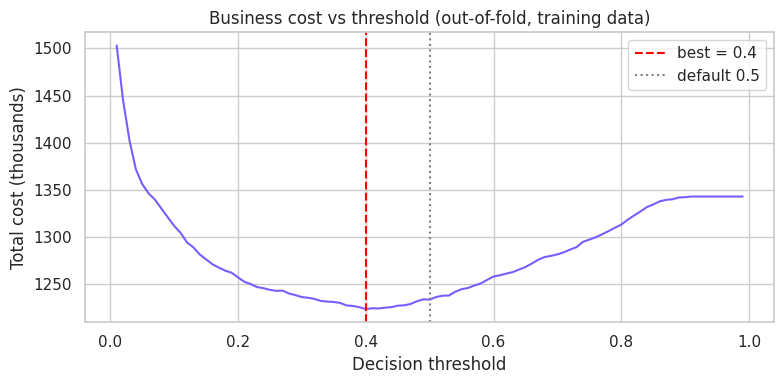

In [31]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds, costs / 1000, color="#7c5cff")
plt.axvline(BEST_THRESHOLD, color="red", ls="--", label=f"best = {BEST_THRESHOLD}")
plt.axvline(0.5, color="gray", ls=":", label="default 0.5")
plt.xlabel("Decision threshold"); plt.ylabel("Total cost (thousands)"); plt.legend()
plt.title("Business cost vs threshold (out-of-fold, training data)")
savefig("10_threshold_cost")

In [32]:
# Sensitivity: how much does the best threshold move if the assumptions change?
rows = []
for oc in [50, 100, 200]:
    for su in [0.2, 0.3, 0.5]:
        c = np.array([total_cost(y_tr, OOF_PROBA, t, value_tr, offer_cost=oc, success=su) for t in thresholds])
        rows.append({"offer_cost": oc, "offer_success": su, "best_threshold": thresholds[c.argmin()]})
pd.DataFrame(rows).pivot(index="offer_cost", columns="offer_success", values="best_threshold")

offer_success,0.2,0.3,0.5
offer_cost,,,
50,0.30,0.21,0.12
100,0.53,0.40,0.21
200,0.90,0.72,0.44


**Reading the result (training data, out-of-fold)**
- The cost-optimal threshold is **0.40**, not 0.5. It flags 1563 customers, catches 964 of the 1495 churners (recall 0.645, precision 0.617) and lowers total cost to about 1.224M, saving about 119k compared with doing nothing.
- Default 0.5 saves about 109k, so the gain from tuning is real but **small**: the cost curve is quite flat around its minimum.
- Targeting **everyone** costs more than targeting nobody, so a model really is needed.
- The sensitivity table shows that the best threshold moves a lot with the assumptions (from 0.12 to 0.90). The threshold is only as good as the cost assumptions.

## 19. Final Test Set Evaluation (Once!)
- Fit the final pipeline on the full training set.
- Now, and only now, use the test set.
- Report PR-AUC, ROC-AUC, precision, recall, F1 and the confusion matrix at the chosen threshold.
- Also report the total cost on the test set.
- Compare with cross-validation scores. They should be similar. If the test score is much better or worse, investigate.
- **Do not go back and change the model because of the test result.**

ChurnGuard (test set) @ threshold 0.40
  pr_auc: 0.658 | roc_auc: 0.847 | precision: 0.598 | recall: 0.652 | f1: 0.624 | brier: 0.135


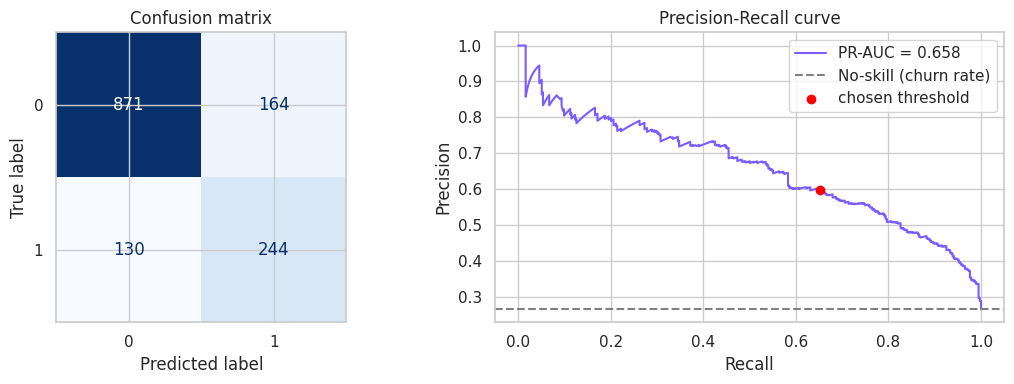


Same model at default 0.5 @ threshold 0.50
  pr_auc: 0.658 | roc_auc: 0.847 | precision: 0.676 | recall: 0.524 | f1: 0.590 | brier: 0.135


In [33]:
# Fit the FINAL model on the full training set. Test set is used here for the first time.
if USE_CALIBRATION:
    final_model = CalibratedClassifierCV(clone(FINAL_PIPE), method=CAL_METHOD, cv=5).fit(X_tr, y_tr)
else:
    final_model = clone(FINAL_PIPE).fit(X_tr, y_tr)
TEST_PROBA = final_model.predict_proba(X_te)[:, 1]

test_res = evaluate_model("ChurnGuard (test set)", final_model, X_te, y_te, threshold=BEST_THRESHOLD)
print()
_ = evaluate_model("Same model at default 0.5", final_model, X_te, y_te, threshold=0.5, plot=False)

In [34]:
cv_row = pd.DataFrame(results).query("model == @BEST_MODEL and strategy == @BEST_STRATEGY").iloc[0]
print(f"CV PR-AUC (train, before tuning): {cv_row.pr_auc_mean:.3f} ± {cv_row.pr_auc_std:.3f}")
print(f"Test PR-AUC                     : {test_res['pr_auc']:.3f}")

test_table = pd.DataFrame([
    policy_summary("Target nobody", y_te, TEST_PROBA, 1.01, value_te),
    policy_summary("Target everyone", y_te, TEST_PROBA, 0.0, value_te),
    policy_summary("Default threshold 0.5", y_te, TEST_PROBA, 0.5, value_te),
    policy_summary("Cost-optimal threshold", y_te, TEST_PROBA, BEST_THRESHOLD, value_te),
])
test_table["saving_vs_nobody"] = test_table.loc[0, "total_cost"] - test_table["total_cost"]
test_table.round(3)

CV PR-AUC (train, before tuning): 0.664 ± 0.018
Test PR-AUC                     : 0.658


,policy,threshold,customers_flagged,churners_caught,recall,precision,total_cost,saving_vs_nobody
0,Target nobody,1.01,0,0,0.000,0.000,326578.80,0.00
1,Target everyone,0.00,1409,374,1.000,0.265,369505.16,-42926.36
2,Default threshold 0.5,0.50,290,196,0.524,0.676,301512.02,25066.78
3,Cost-optimal threshold,0.40,408,244,0.652,0.598,300936.30,25642.50


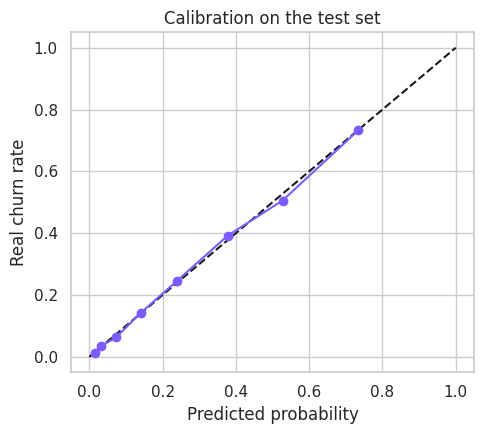

In [35]:
frac_pos, mean_pred = calibration_curve(y_te, TEST_PROBA, n_bins=8, strategy="quantile")
plt.figure(figsize=(5, 4.5))
plt.plot([0, 1], [0, 1], "k--"); plt.plot(mean_pred, frac_pos, "o-", color="#7c5cff")
plt.xlabel("Predicted probability"); plt.ylabel("Real churn rate"); plt.title("Calibration on the test set")
savefig("11_calibration_test")

**Reading the final test result (used once)**
- Test PR-AUC **0.658** vs CV PR-AUC 0.664, ROC-AUC 0.847: consistent, so no sign of leakage or overfitting.
- At threshold 0.40: precision 0.598, recall 0.652, F1 0.624. At 0.5: precision 0.676, recall 0.524.
- Business cost on the test set: saving of about 25.6k vs doing nothing at threshold 0.40 and 25.1k at 0.5. Targeting everyone would lose about 43k.
- We do **not** go back and change anything because of these numbers.

## 20. SHAP Explanations
### 20.1 Prepare
- Take the trained classifier out of the pipeline and the transformed data from the preprocessor.
- Keep the readable feature names after one-hot encoding.
- Use the tree explainer for tree models.
- Think about whether you explain the raw model or the calibrated model, and write down your choice.

### 20.2 Global explanation
- Draw the SHAP summary plot (and optionally the bar plot).
- Write which features matter most and in which direction. Compare with your EDA findings. They should agree.

### 20.3 Local explanation
- Pick 3 customers: one high risk, one medium risk and one low risk.
- Draw a waterfall plot for each one.
- Explain each in simple words: "This customer is at risk because ..."

### 20.4 Top 3 reasons
- Plan a function that, for any customer, returns the **3 features that push the risk up the most**.
- Translate technical names into human text (for example a one-hot column name into a readable sentence).
- This will be reused in the Gradio app. Every prediction in the app must show these 3 reasons.

#### 20.1 Prepare

In [36]:
# Fit an un-calibrated copy of the final pipeline so we can open it up for SHAP
explain_pipe = clone(FINAL_PIPE).fit(X_tr, y_tr)
prep = explain_pipe.named_steps["prep"]
clf = explain_pipe.named_steps["clf"]
feature_names = list(prep.get_feature_names_out())
X_te_t = pd.DataFrame(prep.transform(X_te), columns=feature_names, index=X_te.index)

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_te_t)
print("SHAP matrix:", np.shape(shap_values), "| features after encoding:", len(feature_names))

SHAP matrix: (1409, 45) | features after encoding: 45


#### 20.2 Global explanation

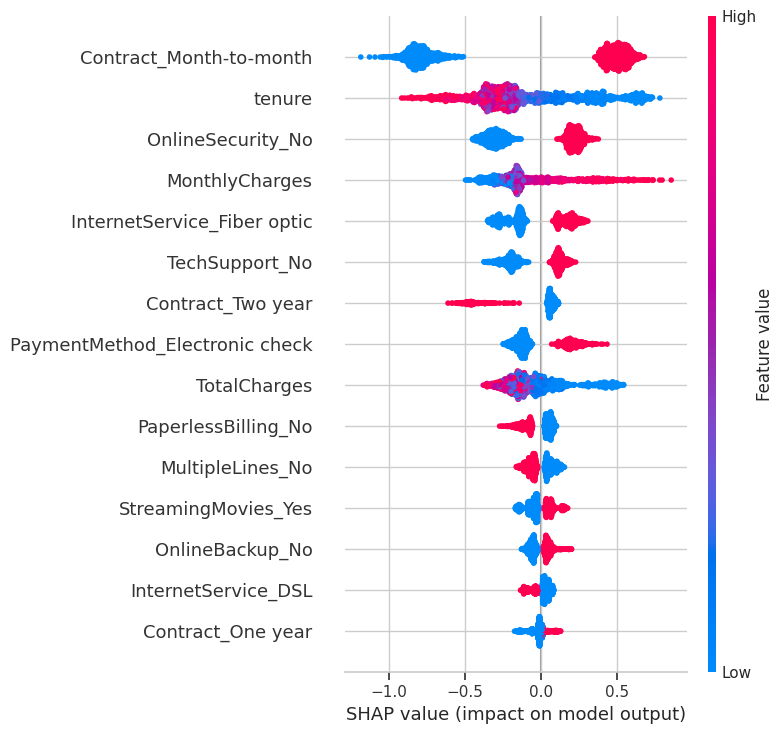

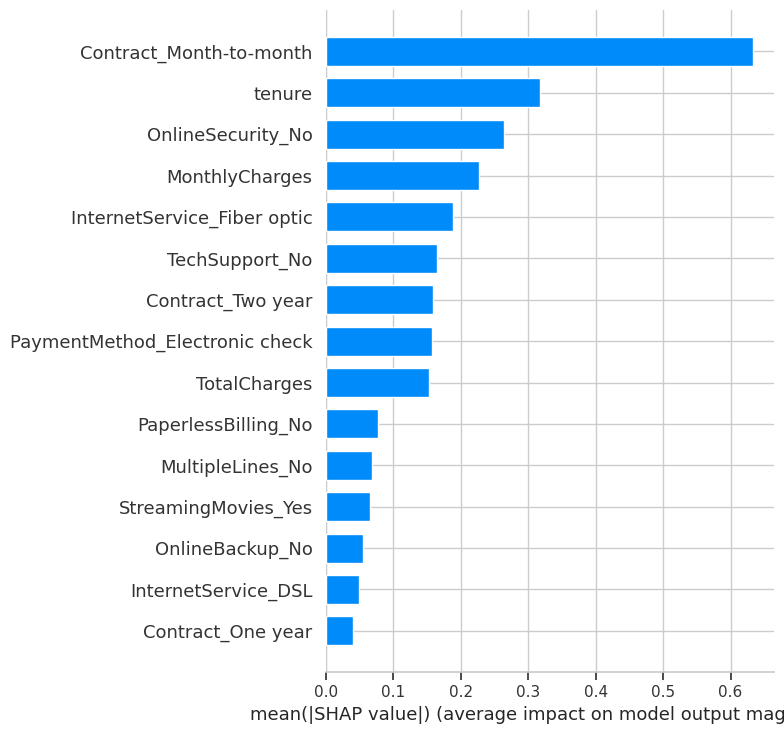

In [37]:
shap.summary_plot(shap_values, X_te_t, show=False, max_display=15)
savefig("12_shap_summary")
shap.summary_plot(shap_values, X_te_t, plot_type="bar", show=False, max_display=15)
savefig("13_shap_bar")

#### 20.3 Local explanation (three customers)

HIGH risk customer (test row 1090): churn probability = 0.91, real churn = 1


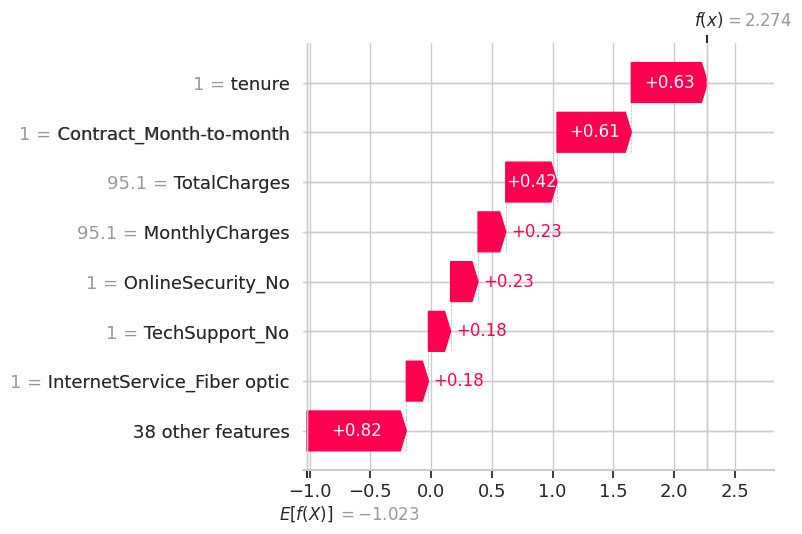

MEDIUM risk customer (test row 950): churn probability = 0.55, real churn = 1


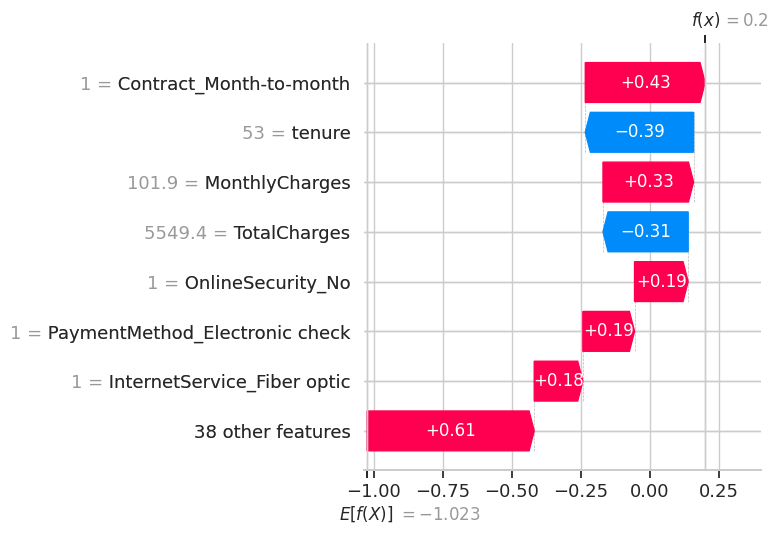

LOW risk customer (test row 262): churn probability = 0.01, real churn = 0


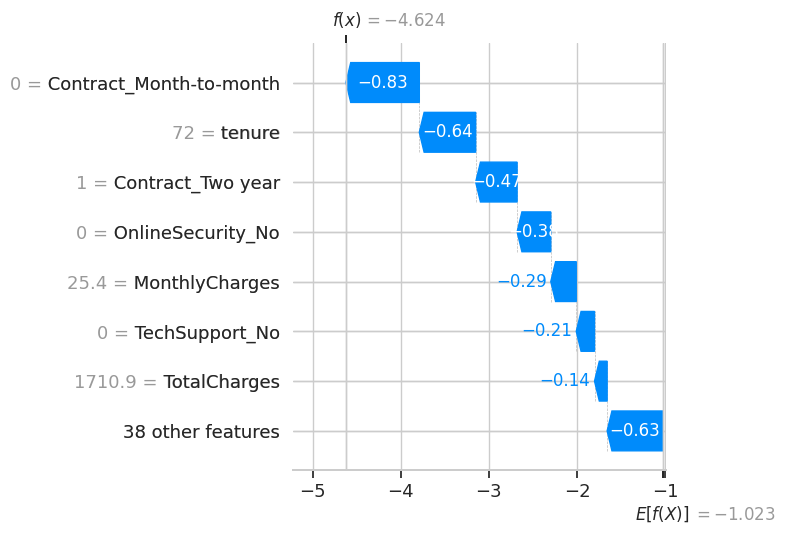

In [38]:
base_value = float(np.ravel(explainer.expected_value)[0])
mid_target = (BEST_THRESHOLD + HIGH_FROM) / 2
picks = {
    "high": int(np.argmax(TEST_PROBA)),
    "medium": int(np.argmin(np.abs(TEST_PROBA - mid_target))),
    "low": int(np.argmin(TEST_PROBA)),
}
for level, i in picks.items():
    print(f"{level.upper()} risk customer (test row {i}): churn probability = {TEST_PROBA[i]:.2f}, real churn = {y_te.iloc[i]}")
    exp = shap.Explanation(values=shap_values[i], base_values=base_value,
                           data=X_te_t.iloc[i].values, feature_names=feature_names)
    shap.plots.waterfall(exp, max_display=8, show=False)
    savefig(f"14_shap_waterfall_{level}")

#### 20.4 Top 3 reasons function (reused later in the app)

In [39]:
RAW_COLS = num_cols + bin_cols + cat_cols

def raw_col_of(feature):
    """Map an encoded feature name (e.g. 'Contract_Two year') back to its raw column ('Contract')."""
    return max([c for c in RAW_COLS if feature == c or feature.startswith(c + "_")], key=len)

FEATURE_TO_RAW = {f: raw_col_of(f) for f in feature_names}
LABELS = {"tenure": "Tenure", "MonthlyCharges": "Monthly charges", "TotalCharges": "Total charges",
          "SeniorCitizen": "Senior citizen", "Contract": "Contract type", "InternetService": "Internet service",
          "PaymentMethod": "Payment method", "TechSupport": "Tech support", "OnlineSecurity": "Online security",
          "OnlineBackup": "Online backup", "DeviceProtection": "Device protection", "StreamingTV": "Streaming TV",
          "StreamingMovies": "Streaming movies", "PaperlessBilling": "Paperless billing",
          "MultipleLines": "Multiple lines", "PhoneService": "Phone service", "Partner": "Has partner",
          "Dependents": "Has dependents", "gender": "Gender"}

def format_value(col, val):
    if pd.isna(val): return "not available"
    if col == "tenure": return f"{int(val)} month" + ("" if int(val) == 1 else "s")
    if col in ("MonthlyCharges", "TotalCharges"): return f"${float(val):,.2f}"
    if col == "SeniorCitizen": return "Yes" if int(val) == 1 else "No"
    return str(val)

def explain_customer(row_df, top_k=3):
    """Top reasons that PUSH the churn risk UP for one customer (row_df = 1-row DataFrame of raw columns)."""
    Xt = pd.DataFrame(prep.transform(row_df[RAW_COLS]), columns=feature_names)
    sv = explainer.shap_values(Xt)[0]
    by_col = pd.Series(sv, index=feature_names).groupby(FEATURE_TO_RAW).sum()     # sum one-hot columns per raw column
    top = by_col.sort_values(ascending=False).head(top_k)
    return [{"feature": c, "reason": f"{LABELS[c]}: {format_value(c, row_df.iloc[0][c])}", "impact": round(float(v), 3)}
            for c, v in top.items() if v > 0]

for level, i in picks.items():
    print(level.upper(), f"(p = {TEST_PROBA[i]:.2f})")
    for r in explain_customer(X_te.iloc[[i]]):
        print("   -", r["reason"], f"(impact {r['impact']:+.2f})")

HIGH (p = 0.91)
   - Contract type: Month-to-month (impact +0.65)
   - Tenure: 1 month (impact +0.63)
   - Total charges: $95.10 (impact +0.42)
MEDIUM (p = 0.55)
   - Contract type: Month-to-month (impact +0.46)
   - Monthly charges: $101.90 (impact +0.33)
   - Internet service: Fiber optic (impact +0.23)
LOW (p = 0.01)
   - Multiple lines: Yes (impact +0.05)
   - Has dependents: No (impact +0.01)
   - Gender: Male (impact +0.01)


**What SHAP tells us**
- **Global:** the most important feature is the month-to-month contract, followed by tenure, no online security, monthly charges, fiber optic internet, no tech support, electronic check and total charges. This matches the EDA, so the model learned sensible things.
- **Local:** for the high-risk customer the top reasons are a month-to-month contract and a tenure of 1 month. For the medium-risk customer they are month-to-month, high monthly charges and fiber optic. The low-risk customer has no strong risk factor.
- `explain_customer()` returns the top 3 reasons that push the risk **up**, summed per original column. It will be reused in the app. If a customer has fewer than 3 risk-increasing factors, fewer reasons are returned. The app should handle that case.

## 21. Error Analysis
- Look at **False Negatives** (churners we missed) and **False Positives** (customers we flagged by mistake) at the chosen threshold.
- Compare their features with correct predictions. What do the missed churners have in common?
- Write 3–4 lines of findings. This is great material for the README limitations and for mentor questions.

In [40]:
err = X_te.copy()
err["actual"] = y_te.values
err["proba"] = TEST_PROBA
err["flagged"] = (TEST_PROBA >= BEST_THRESHOLD).astype(int)
err["outcome"] = np.select(
    [(err.actual == 1) & (err.flagged == 1), (err.actual == 0) & (err.flagged == 1),
     (err.actual == 1) & (err.flagged == 0), (err.actual == 0) & (err.flagged == 0)],
    ["TP", "FP", "FN", "TN"], default="")
print(err["outcome"].value_counts())

summary = err.groupby("outcome").agg(customers=("actual", "size"), avg_tenure=("tenure", "mean"),
                                     avg_monthly=("MonthlyCharges", "mean"), avg_proba=("proba", "mean"))
summary["share_month_to_month"] = err.groupby("outcome")["Contract"].apply(lambda s: (s == "Month-to-month").mean())
summary["share_fiber"] = err.groupby("outcome")["InternetService"].apply(lambda s: (s == "Fiber optic").mean())
summary.round(2)

outcome
TN    871
TP    244
FP    164
FN    130
Name: count, dtype: int64


,customers,avg_tenure,avg_monthly,avg_proba,share_month_to_month,share_fiber
outcome,,,,,,
FN,130,28.18,67.37,0.23,0.66,0.45
FP,164,14.97,77.50,0.56,1.00,0.78
TN,871,41.74,57.84,0.12,0.32,0.27
TP,244,10.22,75.64,0.63,1.00,0.80


In [41]:
# the churners we MISSED (False Negatives): what do they look like?
err[err.outcome == "FN"][["tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod", "proba"]].sort_values("proba").head(10)

,tenure,MonthlyCharges,Contract,InternetService,PaymentMethod,proba
4513,72,92.45,Two year,DSL,Credit card (automatic),0.016449
4386,55,57.55,Two year,DSL,Bank transfer (automatic),0.019130
658,2,19.85,One year,No,Mailed check,0.035062
3790,2,19.30,One year,No,Credit card (automatic),0.035197
2244,34,64.40,One year,DSL,Mailed check,0.038519
2894,48,60.35,One year,DSL,Credit card (automatic),0.041568
5086,45,20.40,One year,No,Electronic check,0.042099
6680,48,95.50,Two year,Fiber optic,Mailed check,0.043609
4078,22,67.50,One year,DSL,Bank transfer (automatic),0.050819
3834,57,70.10,One year,DSL,Bank transfer (automatic),0.067727


**Reading the errors (test set, threshold 0.40)**
- 244 caught churners (TP), 164 false alarms (FP), 130 missed churners (FN), 871 correct "stays" (TN).
- Every TP and FP is on a month-to-month contract: that is the main thing the model flags.
- The **missed churners** (FN) are longer-tenure customers (28 months on average), 66% on month-to-month and the rest on longer contracts. Nothing in the data says they are about to leave, so they look like loyal customers. This is a real **limitation**: the dataset has no behaviour signals such as support calls, usage drops or complaints.

## 22. Business Impact Report
- Rank customers by churn probability.
- For the top 10%, 20% and 30% of customers, calculate:
  - how many customers are targeted
  - how many real churners are caught
  - offer cost spent
  - expected revenue saved (use the offer success rate assumption)
  - net benefit
- Compare with a simple alternative such as targeting random customers.
- Show the result as a small table and a chart.
- **Always write the assumptions next to the numbers.**

In [42]:
n = len(y_te); order = np.argsort(-TEST_PROBA); y_arr = y_te.values
base_rate = y_arr.mean(); avg_val_churner = value_te[y_arr == 1].mean()
rows = []
for pct in [10, 20, 30]:
    k = int(n * pct / 100); idx = order[:k]
    caught = int(y_arr[idx].sum())
    saved = OFFER_SUCCESS * value_te[idx][y_arr[idx] == 1].sum()
    offers = OFFER_COST * k
    rnd_caught = k * base_rate
    rnd_saved = OFFER_SUCCESS * rnd_caught * avg_val_churner
    rows.append({"strategy": f"Top {pct}% by risk", "customers_targeted": k, "churners_caught": caught,
                 "precision": caught / k, "offer_cost": offers, "revenue_saved": saved, "net_benefit": saved - offers,
                 "net_benefit_if_random": rnd_saved - offers})
flag = TEST_PROBA >= BEST_THRESHOLD; k = int(flag.sum())
caught = int(y_arr[flag].sum()); saved = OFFER_SUCCESS * value_te[flag][y_arr[flag] == 1].sum()
rows.append({"strategy": f"Cost-optimal threshold ({BEST_THRESHOLD})", "customers_targeted": k, "churners_caught": caught,
             "precision": caught / k, "offer_cost": OFFER_COST * k, "revenue_saved": saved,
             "net_benefit": saved - OFFER_COST * k,
             "net_benefit_if_random": OFFER_SUCCESS * k * base_rate * avg_val_churner - OFFER_COST * k})
impact = pd.DataFrame(rows)
print(f"Assumptions: customer value = MonthlyCharges x {VALUE_MONTHS}, offer cost = {OFFER_COST}, offer success = {OFFER_SUCCESS:.0%}")
print(f"Test set: {n} customers, {int(y_arr.sum())} real churners, revenue at risk = {value_te[y_arr == 1].sum():,.0f}")
impact.round(2)

Assumptions: customer value = MonthlyCharges x 12, offer cost = 100, offer success = 30%
Test set: 1409 customers, 374 real churners, revenue at risk = 326,579


,strategy,customers_targeted,churners_caught,precision,offer_cost,revenue_saved,net_benefit,net_benefit_if_random
0,Top 10% by risk,140,107,0.76,14000,30678.30,16678.30,-4265.22
1,Top 20% by risk,281,190,0.68,28100,52515.18,24415.18,-8560.90
2,Top 30% by risk,422,248,0.59,42200,67540.50,25340.50,-12856.58
3,Cost-optimal threshold (0.4),408,244,0.60,40800,66442.50,25642.50,-12430.06


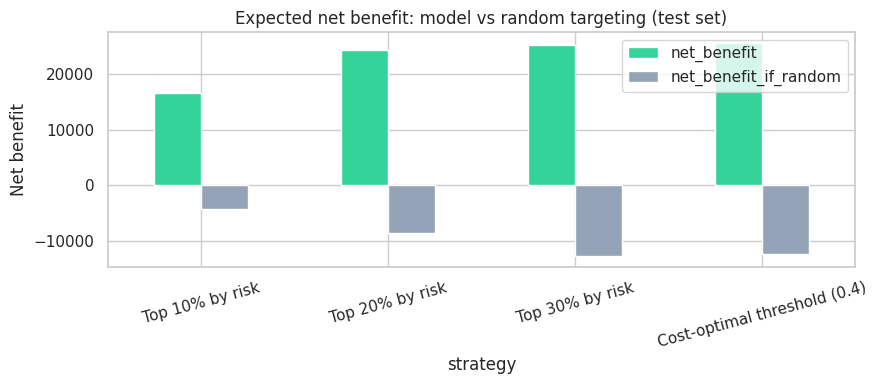

In [43]:
ax = impact.set_index("strategy")[["net_benefit", "net_benefit_if_random"]].plot(kind="bar", figsize=(9, 4), rot=15,
                                                                               color=["#34d399", "#94a3b8"])
ax.set_ylabel("Net benefit"); ax.set_title("Expected net benefit: model vs random targeting (test set)")
savefig("15_business_impact")
impact.to_csv("reports/business_impact.csv", index=False)

**Business impact (assumptions: value = 12 x monthly charges, offer cost 100, offer success 30%)**
- Revenue at risk in the test set: about 326.6k from 374 churners.
- Targeting the **top 20%** by risk (281 customers) catches 190 churners and gives a net benefit of about **24.4k**. Random targeting of the same number of customers would **lose** about 8.6k.
- The cost-optimal threshold (0.40, 408 customers) gives about **25.6k**, almost the same as the top 30%.
- The model is clearly better than random targeting, but the exact money numbers depend completely on the three assumptions.

## 23. Bonus (Extra Credit)
- **Customer Lifetime Value:** estimate each customer's value (for example MonthlyCharges times expected remaining months). Rank by risk x value.
- **Uplift idea:** think about which offer fits which customer. Examples: contract upgrade for month-to-month customers, autopay discount for electronic-check customers, a TechSupport bundle for Fiber customers without support.
- It is fine if the uplift part is a rule-based idea, not a full model. Be honest about it.

In [44]:
# Customer lifetime value idea: rank by EXPECTED loss = churn probability x customer value
bonus = X_te.copy()
bonus["proba"] = TEST_PROBA
bonus["value"] = value_te
bonus["expected_loss"] = bonus["proba"] * bonus["value"]
bonus.sort_values("expected_loss", ascending=False)[["tenure", "MonthlyCharges", "Contract", "proba", "value", "expected_loss"]].head(10).round(2)

,tenure,MonthlyCharges,Contract,proba,value,expected_loss
6894,3,105.90,Month-to-month,0.83,1270.8,1050.79
3956,6,105.30,Month-to-month,0.83,1263.6,1043.45
3085,3,105.35,Month-to-month,0.82,1264.2,1038.12
3380,1,95.10,Month-to-month,0.91,1141.2,1034.75
2797,3,100.95,Month-to-month,0.85,1211.4,1032.06
6866,1,95.45,Month-to-month,0.90,1145.4,1031.79
6365,7,101.95,Month-to-month,0.84,1223.4,1029.97
2631,7,99.25,Month-to-month,0.86,1191.0,1025.74
2246,1,102.45,Month-to-month,0.82,1229.4,1007.91
1073,7,98.05,Month-to-month,0.85,1176.6,994.69


In [45]:
# Uplift idea (rule-based): which offer for which flagged customer?
def suggest_offer(row):
    if row["Contract"] == "Month-to-month":
        return "Contract upgrade offer (discount for a 1-year plan)"
    if row["PaymentMethod"] == "Electronic check":
        return "Autopay discount (switch from electronic check)"
    if row["InternetService"] == "Fiber optic" and row["TechSupport"] == "No":
        return "Free tech-support bundle"
    return "General loyalty discount"

flagged = bonus[bonus["proba"] >= BEST_THRESHOLD].copy()
flagged["suggested_offer"] = flagged.apply(suggest_offer, axis=1)
flagged["suggested_offer"].value_counts()

,count
suggested_offer,
Contract upgrade offer (discount for a 1-year plan),407
Autopay discount (switch from electronic check),1


**Notes**
- The highest expected-loss customers are new, month-to-month customers with high monthly charges (probability above 0.8, value above 1000). They should be called first.
- Almost every flagged customer is on a month-to-month contract, so the rule-based uplift suggestion is almost always the "contract upgrade" offer. This is only an **idea**, not a tested uplift model: we have no data on which offers worked.

## 24. Save the Final Artifacts
Save these so the app can use them without retraining:
- The **final pipeline** (preprocessing + model in one file; wrapped in a calibrator only if calibration helped).
- The **chosen threshold** and the **cost assumptions** (a small JSON or pickle).
- Anything the SHAP explainer needs, or a plan to rebuild it inside the app.
- Result tables and plots into the reports folder.

**Warning:** the app environment must use the **same library versions** as this notebook (especially scikit-learn, xgboost and imbalanced-learn), otherwise loading the saved model can fail. The versions are saved for you.

In [46]:
# 1. Models: final model for probabilities (calibrated only if calibration helped), plain pipeline for SHAP
joblib.dump(final_model, "models/churn_model.joblib")
joblib.dump(explain_pipe, "models/churn_explain_pipeline.joblib")

# 2. Everything the app needs to know
import sklearn, xgboost, imblearn
artifacts = {
    "threshold": BEST_THRESHOLD,
    "risk_levels": {"low_below": BEST_THRESHOLD, "high_from": HIGH_FROM},
    "calibration_method": CAL_METHOD,
    "model": BEST_MODEL, "imbalance_strategy": BEST_STRATEGY,
    "costs": {"value_months": VALUE_MONTHS, "offer_cost": OFFER_COST, "offer_success": OFFER_SUCCESS},
    "features": {"numeric": num_cols, "binary": bin_cols, "categorical": cat_cols},
    "categorical_values": {c: sorted(df[c].unique().tolist()) for c in cat_cols},
    "numeric_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in num_cols},
    "labels": LABELS,
    "test_metrics": {k: float(v) for k, v in test_res.items() if k not in ("model",)},
    "versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                 "imbalanced-learn": imblearn.__version__, "shap": shap.__version__, "pandas": pd.__version__,
                 "numpy": np.__version__},
}
with open("models/artifacts.json", "w") as f:
    json.dump(artifacts, f, indent=2)

# 3. Reports and a sample file for testing the CSV upload in the app
pd.DataFrame(results).to_csv("reports/cv_results.csv", index=False)
test_table.to_csv("reports/test_policy_table.csv", index=False)
X_te.sample(25, random_state=RANDOM_STATE).to_csv("data/sample_customers.csv", index=False)
print(json.dumps(artifacts["versions"], indent=2))
print("Saved:", sorted(os.listdir("models")))

{
  "scikit-learn": "1.6.1",
  "xgboost": "3.4.1",
  "imbalanced-learn": "0.14.2",
  "shap": "0.52.0",
  "pandas": "2.2.3",
  "numpy": "2.1.3"
}
Saved: ['artifacts.json', 'churn_explain_pipeline.joblib', 'churn_model.joblib']


In [47]:
# Safety check: reload the saved model from disk and make sure it gives the same answers
reloaded = joblib.load("models/churn_model.joblib")
sample = pd.read_csv("data/sample_customers.csv")
p_new = reloaded.predict_proba(sample)[:, 1]
p_old = final_model.predict_proba(X_te.loc[X_te.sample(25, random_state=RANDOM_STATE).index])[:, 1]
print("Reloaded model matches original predictions:", np.allclose(p_new, p_old, atol=1e-6))
print("NOTE for the app: run pd.to_numeric(df['TotalCharges'], errors='coerce') on any uploaded CSV before predicting (the Kaggle file stores TotalCharges as text).")
pd.DataFrame({"churn_probability": p_new.round(3), "flagged": p_new >= BEST_THRESHOLD}).head()

Reloaded model matches original predictions: True
NOTE for the app: run pd.to_numeric(df['TotalCharges'], errors='coerce') on any uploaded CSV before predicting (the Kaggle file stores TotalCharges as text).


,churn_probability,flagged
0,0.177,False
1,0.402,True
2,0.015,False
3,0.605,True
4,0.045,False


## 25. What Comes Next (After This Notebook)
1. Move reusable code into `src/` files: data loading and cleaning, preprocessing, training, threshold, explain, predict, business.
2. Build the Gradio app: single customer form, CSV upload, probability, risk level, top 3 reasons.
3. Deploy on Hugging Face Spaces and test the live URL.
4. Write the README: problem, dataset, approach, metric choice, final metrics table, screenshots, how to run, limitations.
5. Record the 2–3 minute demo video.
6. Submit: GitHub URL + live demo URL + video link.

## 26. README Notes (Fill As You Go)
- **Why not accuracy?** Write 2–3 lines with the dummy baseline numbers.
- **Final metrics table:** model, PR-AUC, recall, precision, F1.
- **Threshold decision:** chosen value, cost at that value, cost at 0.5.
- **Leakage prevention:** pipelines + SMOTE only inside the CV loop + test set used once.
- **Limitations:** no support-calls column, one company's data, cost and offer-success assumptions, SMOTE result, calibration quality.

## 27. Mentor Questions Checklist
Be ready to answer these in your own words:
- Why is accuracy misleading here? Why PR-AUC?
- What is data leakage? Where could it happen in this project?
- Why must SMOTE run only inside the training folds?
- Why not use threshold 0.5? How did you choose yours?
- What is calibration and why does it matter for cost decisions?
- What is the difference between global and local SHAP explanations?
- What are the limits of this project?